In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

np.random.seed(42)
tf.random.set_seed(42)

X shape: (1000, 2) | Class counts: [500 500]


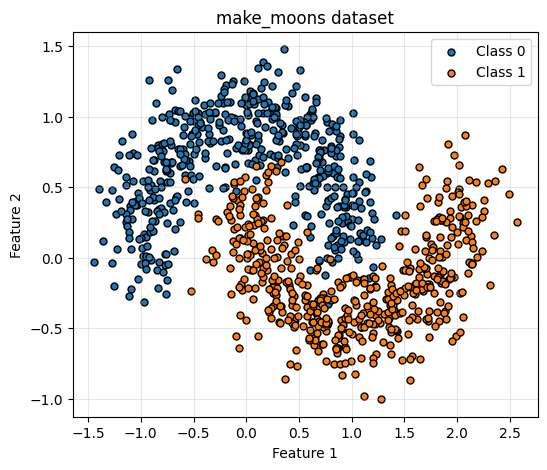

In [2]:
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)
print("X shape:", X.shape, "| Class counts:", np.bincount(y))

plt.figure(figsize=(6,5))
plt.scatter(X[y==0,0], X[y==0,1], c='tab:blue', label='Class 0', edgecolor='k', s=25)
plt.scatter(X[y==1,0], X[y==1,1], c='tab:orange', label='Class 1', edgecolor='k', s=25)
plt.title("make_moons dataset"); plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [4]:
model = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                           restore_best_weights=True)

history = model.fit(X_train_s, y_train,
                    validation_split=0.2,
                    epochs=200,
                    batch_size=32,
                    callbacks=[early_stop],
                    verbose=1)

Epoch 1/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - accuracy: 0.7688 - loss: 0.5494 - val_accuracy: 0.9000 - val_loss: 0.2982
Epoch 2/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8453 - loss: 0.3400 - val_accuracy: 0.9187 - val_loss: 0.2144
Epoch 3/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.8562 - loss: 0.3043 - val_accuracy: 0.9187 - val_loss: 0.2052
Epoch 4/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8625 - loss: 0.2740 - val_accuracy: 0.9187 - val_loss: 0.1828
Epoch 5/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8844 - loss: 0.2405 - val_accuracy: 0.9187 - val_loss: 0.1574
Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9172 - loss: 0.2038 - val_accuracy: 0.9438 - val_loss: 0.1325
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9438 - loss: 0.1718 - val_accuracy: 0.9625 - val_loss: 0.1139
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9531 - loss: 0.1455 - val_accuracy: 0.

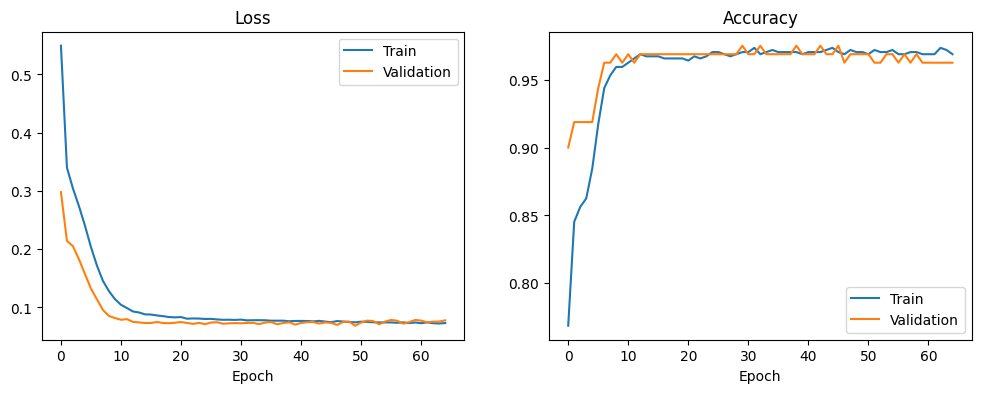

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(history.history['loss'], label='Train')
ax[0].plot(history.history['val_loss'], label='Validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='Train')
ax[1].plot(history.history['val_accuracy'], label='Validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.show()

Test loss: 0.0314 | Test accuracy: 0.9900
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99       100
           1       0.98      1.00      0.99       100

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       0.99      0.99      0.99       200



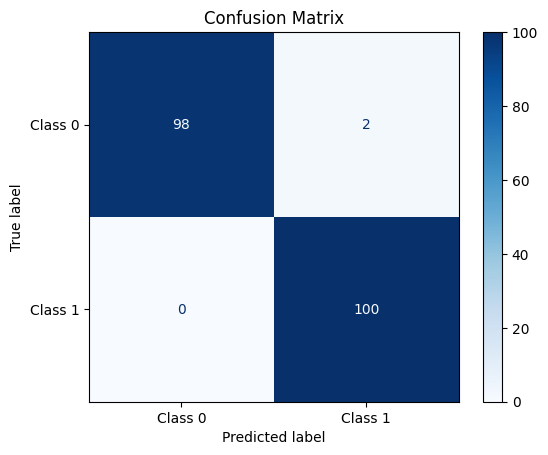

In [7]:
test_loss, test_acc = model.evaluate(X_test_s, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

y_pred = (model.predict(X_test_s) > 0.5).astype(int).ravel()
print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Class 0','Class 1']).plot(cmap='Blues')
plt.title("Confusion Matrix"); plt.show()

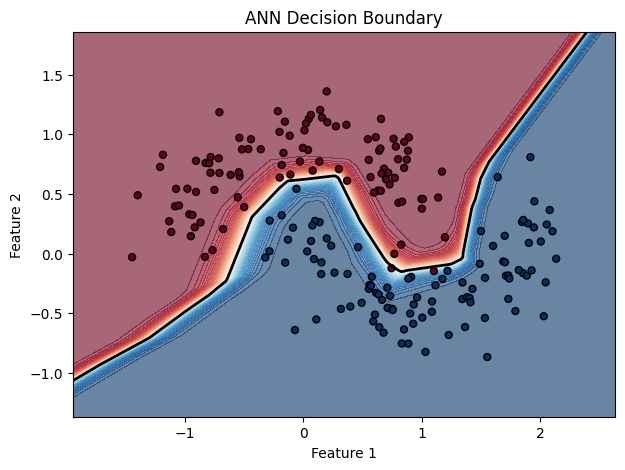

In [8]:
def plot_decision_boundary(model, X, y, scaler):
    x_min, x_max = X[:,0].min()-0.5, X[:,0].max()+0.5
    y_min, y_max = X[:,1].min()-0.5, X[:,1].max()+0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = scaler.transform(np.c_[xx.ravel(), yy.ravel()])
    Z = model.predict(grid, verbose=0).reshape(xx.shape)
    plt.figure(figsize=(7,5))
    plt.contourf(xx, yy, Z, levels=50, cmap='RdBu', alpha=0.6)
    plt.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=2)
    plt.scatter(X[:,0], X[:,1], c=y, cmap='RdBu', edgecolor='k', s=25)
    plt.title("ANN Decision Boundary"); plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
    plt.show()

plot_decision_boundary(model, X_test, y_test, scaler)

In [9]:
new_points = np.array([[0.0, 0.5], [1.0, -0.5], [-1.0, 0.0]])
probs = model.predict(scaler.transform(new_points), verbose=0).ravel()
for p, pr in zip(new_points, probs):
    print(f"Point {p} -> P(class 1) = {pr:.3f} -> Predicted class {int(pr > 0.5)}")

Point [0.  0.5] -> P(class 1) = 0.924 -> Predicted class 1
Point [ 1.  -0.5] -> P(class 1) = 0.999 -> Predicted class 1
Point [-1.  0.] -> P(class 1) = 0.003 -> Predicted class 0
